In [1]:
%%time
#%load_ext autoreload
#%autoreload 2

CPU times: user 10 μs, sys: 4 μs, total: 14 μs
Wall time: 21.7 μs


In [2]:
%%time
import os

import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

CPU times: user 15.3 s, sys: 975 ms, total: 16.3 s
Wall time: 20.9 s


In [3]:
%%time
import sys

sys.path.append("../utils")

import data_io

CPU times: user 60.1 ms, sys: 14.4 ms, total: 74.4 ms
Wall time: 469 ms


# setup

In [4]:
%%time
cm = 1/2.54  # centimeters in inches
plt.style.use('paper.mplstyle')

CPU times: user 1.51 ms, sys: 1.93 ms, total: 3.44 ms
Wall time: 2.98 ms


In [5]:
%%time
order = ["A17", "A2", "nNOS-1", "Other"]

cmap = {"RBC" :  "#0C7C59",
        "A2":    "#134D7C",
        "A17":   "#32A9DE",
        "nNOS-1":    "#B1DEF2",
        "Separate dendrites and axons":    "#B1DEF2",
        "Other": "#1D74B9" }

CPU times: user 16 μs, sys: 0 ns, total: 16 μs
Wall time: 26 μs


# load data

In [6]:
%%time
config = data_io.get_data_config()
version = config.get("version_rbc", None)
file_path_celltypes = data_io.get_file_path(config,
                                  version = "version_rbc",
                                  file_prefix = "file_prefix_rbc_celltypes")

file_path_synapses = data_io.get_file_path(config,
                                  version = "version_rbc",
                                  file_prefix = "file_prefix_rbc_synapses")

CPU times: user 2.36 ms, sys: 1.93 ms, total: 4.29 ms
Wall time: 4 ms


In [7]:
%%time
assert os.path.isfile(file_path_celltypes), file_path_celltypes
assert os.path.isfile(file_path_synapses), file_path_synapses

CPU times: user 487 μs, sys: 0 ns, total: 487 μs
Wall time: 474 μs


In [8]:
%%time
celltype_df = pd.read_parquet(file_path_celltypes)
synapses_df = pd.read_parquet(file_path_synapses)

CPU times: user 74.6 ms, sys: 63.8 ms, total: 138 ms
Wall time: 987 ms


In [9]:
%%time
synapses_df

CPU times: user 19 μs, sys: 2 μs, total: 21 μs
Wall time: 38.4 μs


,pt_pre,pt_post,synapse_type,source,target,source_type,source_class,target_type,target_class
0,"[42722.28125, 36208.04296875, 715.5]","[42701.76171875, 36195.828125, 715.5]",ribbon,720575940567417708,720575940544951525,dA17 large,AC,None,None
1,"[42522.703125, 36251.7890625, 825.5000610351562]","[42545.6640625, 36253.25390625, 825.5000610351...",ribbon,720575940567417708,720575940569769761,dA17 large,AC,RBC,BC
2,"[42511.91015625, 36248.5, 808.592529296875]","[42528.5234375, 36248.5, 805.4657592773438]",ribbon,720575940567417708,720575940569769761,dA17 large,AC,RBC,BC
3,"[43207.765625, 35503.5625, 774.5000610351562]","[43228.7734375, 35498.1875, 774.5000610351562]",ribbon,720575940567417708,720575940556472535,dA17 large,AC,RBC,BC
4,"[42456.55859375, 36071.84375, 757.5]","[42458.0234375, 36095.296875, 757.5]",ribbon,720575940567417708,720575940569769761,dA17 large,AC,RBC,BC
...,...,...,...,...,...,...,...,...,...
447,"[42534.34375, 36230.69140625, 780.5]","[42534.8828125, 36244.63671875, 780.5]",conventional,720575940569769761,720575940567654385,RBC,BC,A2,AC
448,"[42466.52734375, 36115.5, 744.1353759765625]","[42473.76953125, 36115.5, 736.7350463867188]",conventional,720575940569769761,720575940553132481,RBC,BC,A2,AC
449,"[42760.1015625, 36536.66796875, 697.4999389648...","[42772.703125, 36536.1328125, 700.5]",conventional,720575940569769761,720575940567989001,RBC,BC,None,None
450,"[42720.546875, 36484.36328125, 640.4852905273438]","[42729.66015625, 36472.03125, 640.4852905273438]",conventional,720575940569769761,720575940567654385,RBC,BC,A2,AC


## rename celltypes

In [10]:
# plot counts of split cell labels 
celltype_df.value_counts("Cell Type")  # mention in figure legend

Cell Type
A17 large                       35
A17 small                       16
RBC                              9
nNOS-1                           8
A2                               4
dA17 large                       2
H42                              2
Other                            1
H52                              1
VIP1 (VIPm)                      1
Separate dendrites and axons     1
Name: count, dtype: int64

In [11]:
%%time
celltype_df = celltype_df.replace("A17 large", 'A17')       # remove distinction for simplicity
celltype_df = celltype_df.replace("A17 small", 'A17')
celltype_df = celltype_df.replace("dA17 large", 'A17')

celltype_df = celltype_df.replace("H42", 'Other')           # preliminary prediction, remove for manuscript
celltype_df = celltype_df.replace("H52", 'Other')

celltype_df = celltype_df.replace("A1", 'n-NOS1')           # overwrite preliminary name given by classifier



CPU times: user 1.93 ms, sys: 0 ns, total: 1.93 ms
Wall time: 1.81 ms


In [12]:
%%time
synapses_df[['source_type', 'target_type']] = synapses_df[['source_type', 'target_type']].replace("A17 large", 'A17')
synapses_df[['source_type', 'target_type']] = synapses_df[['source_type', 'target_type']].replace("A17 small", 'A17')
synapses_df[['source_type', 'target_type']] = synapses_df[['source_type', 'target_type']].replace("dA17 large", 'A17')

synapses_df[['source_type', 'target_type']] = synapses_df[['source_type', 'target_type']].replace("H42", 'Other')
synapses_df[['source_type', 'target_type']] = synapses_df[['source_type', 'target_type']].replace("H52", 'Other')

synapses_df[['source_type', 'target_type']] = synapses_df[['source_type', 'target_type']].replace("A1", 'nNOS-1')

CPU times: user 5.02 ms, sys: 2 ms, total: 7.02 ms
Wall time: 6.38 ms


In [13]:
%%time
len(synapses_df), len(celltype_df)

CPU times: user 15 μs, sys: 1e+03 ns, total: 16 μs
Wall time: 25 μs


(452, 124)

# overview

In [14]:
%%time
celltype_df.value_counts("Cell Type")  # all connections that occur only once will be filtered out

CPU times: user 874 μs, sys: 0 ns, total: 874 μs
Wall time: 825 μs


Cell Type
A17                             53
RBC                              9
nNOS-1                           8
Other                            4
A2                               4
Separate dendrites and axons     1
VIP1 (VIPm)                      1
Name: count, dtype: int64

## output connections 

In [15]:
%%time
### get all synapses from RBC ###
cell_type = "RBC"
synapses_out = synapses_df[synapses_df['source_type'] == cell_type]
# ct_ids = np.unique(synapses_out['source'].values)
# len(ct_ids), len(synapses_out)

CPU times: user 699 μs, sys: 0 ns, total: 699 μs
Wall time: 656 μs


In [16]:
%%time
### remoove those which appear only once from type to type  ### 
counts = synapses_out.groupby(["source_type", "target_type"]).transform("size")
synapses_out = synapses_out[counts > 1]

CPU times: user 2.24 ms, sys: 1.02 ms, total: 3.26 ms
Wall time: 3.04 ms


In [17]:
%%time
### count synapses ##
synapse_counts = synapses_out.value_counts(subset = ['target_type'])
print('total output synapses per postsynaptic cell type')
print('------------------')
synapse_counts

total output synapses per postsynaptic cell type
------------------
CPU times: user 1.53 ms, sys: 0 ns, total: 1.53 ms
Wall time: 1.41 ms


target_type
A2             122
A17            103
nNOS-1           3
Name: count, dtype: int64

In [18]:
%%time
## count postsynaptic cells ###
celltype_counts = synapses_out.value_counts(subset = ['target_type'])
print('total output synapses per postsynaptic cell type')
print('------------------')
celltype_counts

total output synapses per postsynaptic cell type
------------------
CPU times: user 1.29 ms, sys: 24 μs, total: 1.31 ms
Wall time: 1.17 ms


target_type
A2             122
A17            103
nNOS-1           3
Name: count, dtype: int64

## input connections

In [19]:
%%time
### get all synapses from RBC ###

cell_type = "RBC"
synapses_in = synapses_df[synapses_df['target_type'] == cell_type]
# # synapses_in = synapses_df[synapses_df['target'].isin(segments)]
# ct_ids = np.unique(synapses_out['source'].values)
# ct_ids

# len(ct_ids), len(synapses_in)

CPU times: user 649 μs, sys: 0 ns, total: 649 μs
Wall time: 586 μs


In [20]:
%%time
### remoove those which appear only once from type to type  ### 
counts = synapses_in.groupby(["source_type", "target_type"]).transform("size")
synapses_in = synapses_in[counts > 1]

CPU times: user 2.75 ms, sys: 0 ns, total: 2.75 ms
Wall time: 2.5 ms


In [21]:
%%time
### count synapses ##

celltype_counts = synapses_in.value_counts(subset = ['source_type'])
print('total input synapses per presynaptic cell type')
print('------------------')

celltype_counts

total input synapses per presynaptic cell type
------------------
CPU times: user 927 μs, sys: 901 μs, total: 1.83 ms
Wall time: 1.51 ms


source_type
A17            118
Other           12
nNOS-1           7
Name: count, dtype: int64

In [22]:
%%time
## count pre-synaptic cells ###
celltype_counts = synapses_in.value_counts(subset = ['source_type'])
print('total input synapses per presynaptic cell type')
print('------------------')
celltype_counts

total input synapses per presynaptic cell type
------------------
CPU times: user 1.31 ms, sys: 0 ns, total: 1.31 ms
Wall time: 1.18 ms


source_type
A17            118
Other           12
nNOS-1           7
Name: count, dtype: int64

# figures

In [23]:
%%time
version_out = config.get("version", None)
fig_dir = f'../figures/connectivity/v{version_out}'   # saved the figure into the folder of the latest general version for completeness. 

os.makedirs(fig_dir, exist_ok=True)

CPU times: user 1.05 ms, sys: 5 μs, total: 1.05 ms
Wall time: 1.64 ms


In [24]:
%%time
# celltype_counts = synapses_out.value_counts(subset = ['target_type'])
# print('total output synapses per postsynaptic cell type')
# celltype_counts

CPU times: user 11 μs, sys: 0 ns, total: 11 μs
Wall time: 21 μs


In [25]:
%%time
# get all outgoing synapses per RBC per postsynaptic cell
celltype_counts = synapses_out.value_counts(subset = ['target_type', 'source'])   # count synapses per cell to target type
celltype_counts = pd.DataFrame(celltype_counts)
celltype_counts = celltype_counts.reset_index()
celltype_counts = celltype_counts.sort_values('target_type')

celltype_counts_out = celltype_counts
celltype_counts_out

CPU times: user 5.22 ms, sys: 0 ns, total: 5.22 ms
Wall time: 4.62 ms


,target_type,source,count
13,A17,720575940556018391,1
2,A17,720575940569769761,44
3,A17,720575940569047073,33
4,A17,720575940556472535,16
12,A17,720575940555250903,1
7,A17,720575940569043745,5
9,A17,720575940569780257,3
0,A2,720575940569769761,50
11,A2,720575940556018391,2
10,A2,720575940555250903,2


## panel D : outputs barplot

CPU times: user 154 ms, sys: 12.8 ms, total: 166 ms
Wall time: 267 ms


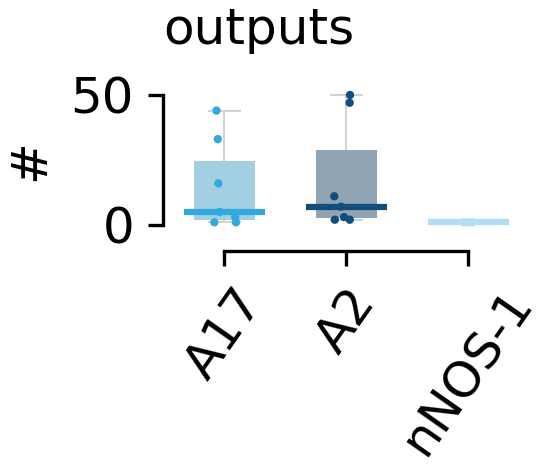

In [26]:
%%time
degree_type = 'count'
order = ["A17", "A2", "nNOS-1"]
box_width = 0.5   

fig  = plt.figure(figsize = (4*cm,2*cm))
ax = fig.add_subplot(111)

sns.boxplot(data = celltype_counts_out, x = 'target_type', y = degree_type,
            hue = 'target_type', order = order, palette = cmap,
            linewidth=0,
            width=box_width,
            whis=1,
            showfliers=False,
            medianprops=dict(linewidth=0),   # hide seaborn's median; redrawn below
            boxprops=dict(edgecolor='none'),
            whiskerprops=dict(linewidth=.5, color='lightgrey', linestyle='-'),
            capprops=dict(linewidth=.5, color='lightgrey'),
            flierprops = dict(marker='o', markerfacecolor='None', markersize=.5,  markeredgecolor='lightgrey'),
            ax=ax)


# ── Set box alpha ──────────────────────────────────────────────────────────
for patch in ax.patches:
    if isinstance(patch, mpatches.FancyBboxPatch):
        continue
    patch.set_alpha(0.5)

# ── Redraw median lines from tick index, not patch geometry ────────────────
# When hue == x (one hue level per cell type, no dodging), each cell type's
# box centre sits exactly at its integer tick index.
half_w  = box_width / 2
med_ext = 0.08   # how much the median line extends beyond each box edge

for i, label in enumerate(order):
    col_data = celltype_counts_out.loc[celltype_counts_out['target_type'] == label, degree_type].dropna()
    if col_data.empty:
        continue
    median_val = col_data.median()
    color = cmap.get(label, 'grey')

    ax.plot([i - half_w - med_ext, i + half_w + med_ext],
            [median_val, median_val],
            color=color, lw=1.5, solid_capstyle='butt',
            zorder=5, transform=ax.transData)


sns.stripplot(data = celltype_counts_out, x = 'target_type', y = degree_type,
              palette = cmap,
              hue = 'target_type',
              size = 2,
              order = order)


plt.xticks(rotation = 55)
plt.ylim(-10,60)

ax.set_ylabel("#")
ax.set_xlabel("")

sns.despine(trim = True)


# ax.set_title(f"{cell_type} outputs", loc = 'left')
ax.set_title(f"outputs", loc = 'left')
fig.savefig(f'{fig_dir}/fig8_D_outputs_boxplot.svg')

## panel D : inputs barplot

In [27]:
%%time
celltype_counts = synapses_in.value_counts(subset = ['source_type', 'target'])
celltype_counts = pd.DataFrame(celltype_counts)
celltype_counts = celltype_counts.reset_index()
celltype_counts = celltype_counts.sort_values('source_type')
# cell_types = list(celltype_counts['source_type'])
celltype_counts_in = celltype_counts

CPU times: user 2.57 ms, sys: 898 μs, total: 3.47 ms
Wall time: 3.07 ms


In [28]:
%%time
celltype_counts_in

CPU times: user 9 μs, sys: 1 μs, total: 10 μs
Wall time: 18.4 μs


,source_type,target,count
0,A17,720575940569769761,41
1,A17,720575940569043745,37
2,A17,720575940569047073,23
3,A17,720575940556472535,8
5,A17,720575940556018391,4
8,A17,720575940555250903,2
9,A17,720575940569780257,2
11,A17,720575940554483198,1
4,Other,720575940569047073,6
7,Other,720575940569043745,3


CPU times: user 106 ms, sys: 4.74 ms, total: 111 ms
Wall time: 109 ms


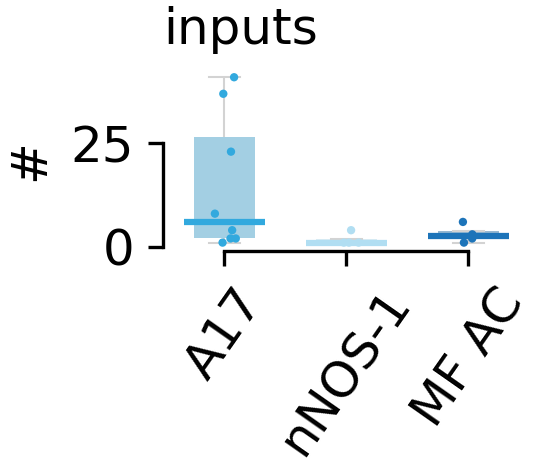

In [29]:
%%time
degree_type = 'count'

order = ["A17", "nNOS-1", "Other"]

fig  = plt.figure(figsize = (4*cm,2*cm))
ax = fig.add_subplot(111)

sns.boxplot(data = celltype_counts_in, x = 'source_type', y = degree_type,
            hue = 'source_type', order = order, palette = cmap,
            linewidth=0,
            width=box_width,
            whis=1,
            showfliers=False,
            medianprops=dict(linewidth=0),   # hide seaborn's median; redrawn below
            boxprops=dict(edgecolor='none'),
            whiskerprops=dict(linewidth=.5, color='lightgrey', linestyle='-'),
            capprops=dict(linewidth=.5, color='lightgrey'),
            flierprops = dict(marker='o', markerfacecolor='None', markersize=.5,  markeredgecolor='lightgrey'),
            ax=ax)


# ── Set box alpha ──────────────────────────────────────────────────────────
for patch in ax.patches:
    if isinstance(patch, mpatches.FancyBboxPatch):
        continue
    patch.set_alpha(0.5)

# ── Redraw median lines from tick index, not patch geometry ────────────────
# When hue == x (one hue level per cell type, no dodging), each cell type's
# box centre sits exactly at its integer tick index.
half_w  = box_width / 2
med_ext = 0.08   # how much the median line extends beyond each box edge

for i, label in enumerate(order):
    col_data = celltype_counts_in.loc[celltype_counts_in['source_type'] == label, degree_type].dropna()
    if col_data.empty:
        continue
    median_val = col_data.median()
    color = cmap.get(label, 'grey')

    ax.plot([i - half_w - med_ext, i + half_w + med_ext],
            [median_val, median_val],
            color=color, lw=1.5, solid_capstyle='butt',
            zorder=5, transform=ax.transData)


sns.stripplot(data = celltype_counts_in, x = 'source_type', y = degree_type,
              palette = cmap,
              hue = 'source_type',
              size = 2,
              order = order)

plt.xticks(rotation = 55)


sns.despine(trim = True)
ax.set_ylabel("#")
ax.set_xlabel("")
ax.set_xticklabels(["A17", "nNOS-1", "MF AC"])


ax.set_title(f"inputs", loc = 'left')
fig.savefig(f'{fig_dir}/fig8_D_inputs_boxplot.svg')

In [30]:
from watermark import watermark
print(watermark())

Last updated: 2026-11-13T17:55:58.503564+01:00

Python implementation: CPython
Python version       : 3.13.3
IPython version      : 9.13.0

Compiler    : Clang 20.1.0 
OS          : Linux
Release     : 5.14.0-687.10.1.el9_8.0.1.x86_64
Machine     : x86_64
Processor   : x86_64
CPU cores   : 48
Architecture: 64bit

